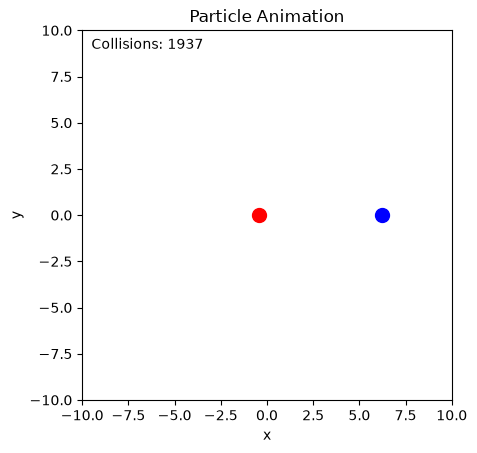

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

# Simulation parameters
dt = 0.001            # kleine tijdstap, tegen "tunnelen" bij hoge snelheden
steps_per_frame = 50  # simulatiestappen per getekend frame
num_frames = 600
L = 10                # muren op x, y = +-L


class ParticleClass:
    def __init__(self, m, v, r, R):
        self.m = m
        self.v = np.array(v, dtype=float)
        self.r = np.array(r, dtype=float)
        self.R = R

    def update_position(self):
        self.r += self.v * dt

    def collide_detection(self, other):
        dr = self.r - other.r
        dv = self.v - other.v
        overlapping = np.dot(dr, dr) <= (self.R + other.R) ** 2
        approaching = np.dot(dv, dr) < 0      # alleen botsen als ze naar elkaar toe bewegen
        return overlapping and approaching


particleA = ParticleClass(m=1, v=[0, 0], r=[-4.0, 0.0], R=0.45)
particleB = ParticleClass(m=1000000000, v=[-1, 0], r=[-2.0, 0.0], R=0.45)
particles = (particleA, particleB)

counter = 0

# Figure
fig, ax = plt.subplots()
ax.set_xlim(-L, L)
ax.set_ylim(-L, L)
ax.set_aspect('equal')
ax.set_title("Particle Animation")
ax.set_xlabel("x")
ax.set_ylabel("y")

dotA, = ax.plot([], [], 'ro', markersize=10)
dotB, = ax.plot([], [], 'bo', markersize=10)
counter_text = ax.text(-9.5, 9, "")


def step():
    """Eén simulatiestap: bewegen, deeltjes laten botsen, muren afhandelen."""
    global counter

    for p in particles:
        p.update_position()

    # botsing tussen de deeltjes
    if particleA.collide_detection(particleB):
        counter += 1
        vA, vB = particleA.v, particleB.v
        mA, mB = particleA.m, particleB.m
        dr = particleA.r - particleB.r
        d2 = np.dot(dr, dr)
        vA_new = vA - 2 * mB / (mA + mB) * np.dot(vA - vB, dr) / d2 * dr
        vB_new = vB + 2 * mA / (mA + mB) * np.dot(vA - vB, dr) / d2 * dr
        particleA.v = vA_new
        particleB.v = vB_new

    # botsing met de muren (alleen als het deeltje naar buiten beweegt)
    for p in particles:
        for i in range(2):
            if abs(p.r[i]) + p.R > L and p.r[i] * p.v[i] > 0:
                p.v[i] = -p.v[i]
                if p is particleA and i == 0:
                    counter += 1


def init():
    dotA.set_data([], [])
    dotB.set_data([], [])
    counter_text.set_text("")
    return dotA, dotB, counter_text


def update(frame):
    for _ in range(steps_per_frame):
        step()

    dotA.set_data([particleA.r[0]], [particleA.r[1]])
    dotB.set_data([particleB.r[0]], [particleB.r[1]])
    counter_text.set_text(f"Collisions: {counter}")
    return dotA, dotB, counter_text


ani = FuncAnimation(fig, update, frames=range(num_frames), init_func=init,
                    blit=True, interval=20)

# Voor Jupyter notebook:
from IPython.display import HTML
HTML(ani.to_jshtml())